In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
path = "/content/drive/MyDrive/housing.csv"
df = pd.read_csv(path)

In [5]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [8]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


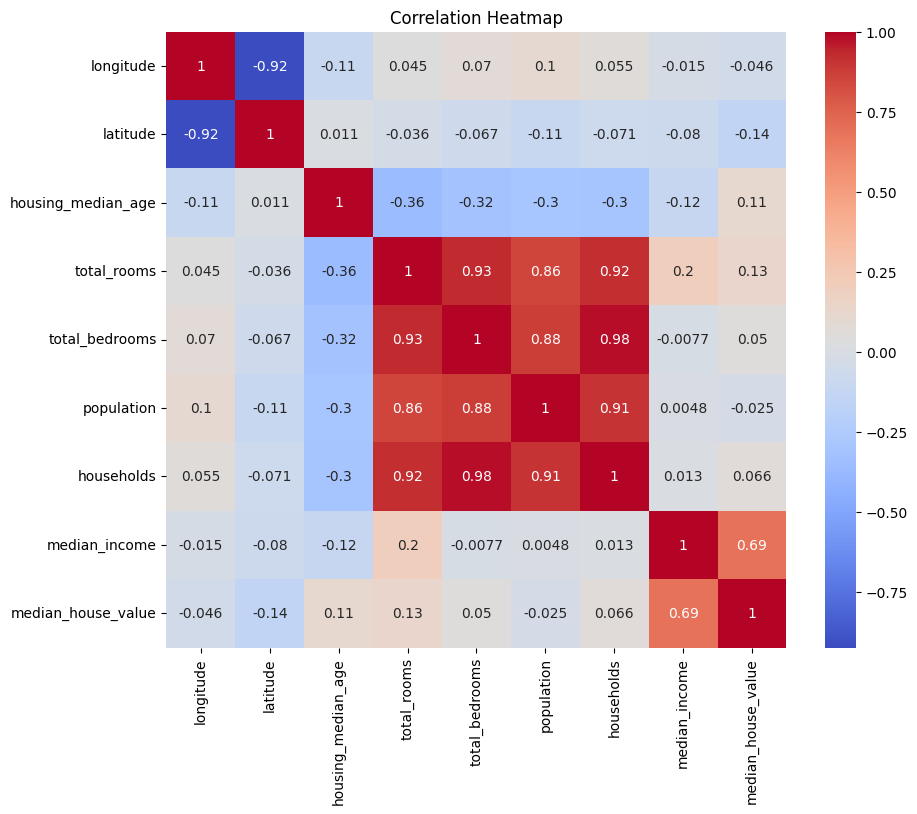

In [9]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

In [10]:
median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'].fillna(median_bedrooms, inplace=True)

df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20640 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   ocean_proximity_INLAND      20640 non-null  bool   
 10  ocean_proximity_ISLAND      20640 non-null  bool   
 11  ocean_proximity_NEAR BAY    20640 non-null  bool   
 12  ocean_proximity_NEAR OCEAN  20640 non-null  bool   
dtypes: bool(4), float64(9)
memory u

In [12]:
df['rooms_per_household'] = df['total_rooms'] / df['households']

df['population_per_household'] = df['population'] / df['households']

In [13]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20640 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   ocean_proximity_INLAND      20640 non-null  bool   
 10  ocean_proximity_ISLAND      20640 non-null  bool   
 11  ocean_proximity_NEAR BAY    20640 non-null  bool   
 12  ocean_proximity_NEAR OCEAN  20640 non-null  bool   
 13  rooms_per_household         206

In [15]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"RMSE (Sai số trung bình): {rmse:.2f}")
print(f"R2 Score (Độ chính xác): {r2:.4f}")

RMSE (Sai số trung bình): 69830.43
R2 Score (Độ chính xác): 0.6279


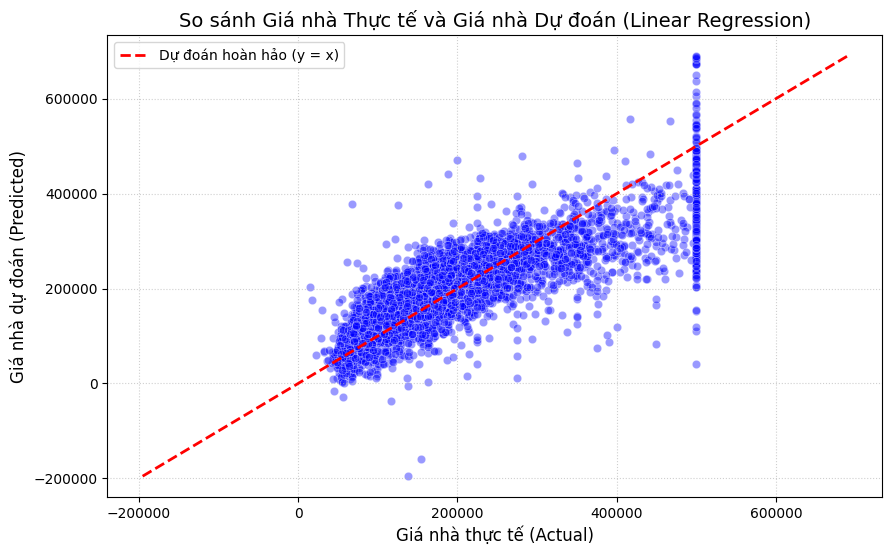

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.4, color='blue', edgecolor='w')

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Dự đoán hoàn hảo (y = x)')

plt.title('So sánh Giá nhà Thực tế và Giá nhà Dự đoán (Linear Regression)', fontsize=14)
plt.xlabel('Giá nhà thực tế (Actual)', fontsize=12)
plt.ylabel('Giá nhà dự đoán (Predicted)', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

In [17]:
path = "/content/drive/MyDrive/housing.csv"
df = pd.read_csv(path)

median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'].fillna(median_bedrooms, inplace=True)
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['population_per_household'] = df['population'] / df['households']

num_cols = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'population_per_household']

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean = df[~((df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)).any(axis=1)]

print(f"Kích thước dữ liệu gốc: {df.shape}")
print(f"Kích thước dữ liệu sau khi loại bỏ ngoại lai: {df_clean.shape}")
print(f"Số lượng bản ghi ngoại lai đã bị loại bỏ: {len(df) - len(df_clean)}")

X_clean = df_clean.drop('median_house_value', axis=1)
y_clean = df_clean['median_house_value']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)

scaler_c = StandardScaler()
X_train_scaled_c = scaler_c.fit_transform(X_train_c)
X_test_scaled_c = scaler_c.transform(X_test_c)

model_c = LinearRegression()
model_c.fit(X_train_scaled_c, y_train_c)
y_pred_c = model_c.predict(X_test_scaled_c)

rmse_c = np.sqrt(mean_squared_error(y_test_c, y_pred_c))
r2_c = r2_score(y_test_c, y_pred_c)

print(f"\nSau khi xử lý ngoại lai:")
print(f"RMSE mới: {rmse_c:.2f}")
print(f"R2 Score mới: {r2_c:.4f}")

Kích thước dữ liệu gốc: (20640, 15)
Kích thước dữ liệu sau khi loại bỏ ngoại lai: (17262, 15)
Số lượng bản ghi ngoại lai đã bị loại bỏ: 3378

Sau khi xử lý ngoại lai:
RMSE mới: 62686.02
R2 Score mới: 0.6456


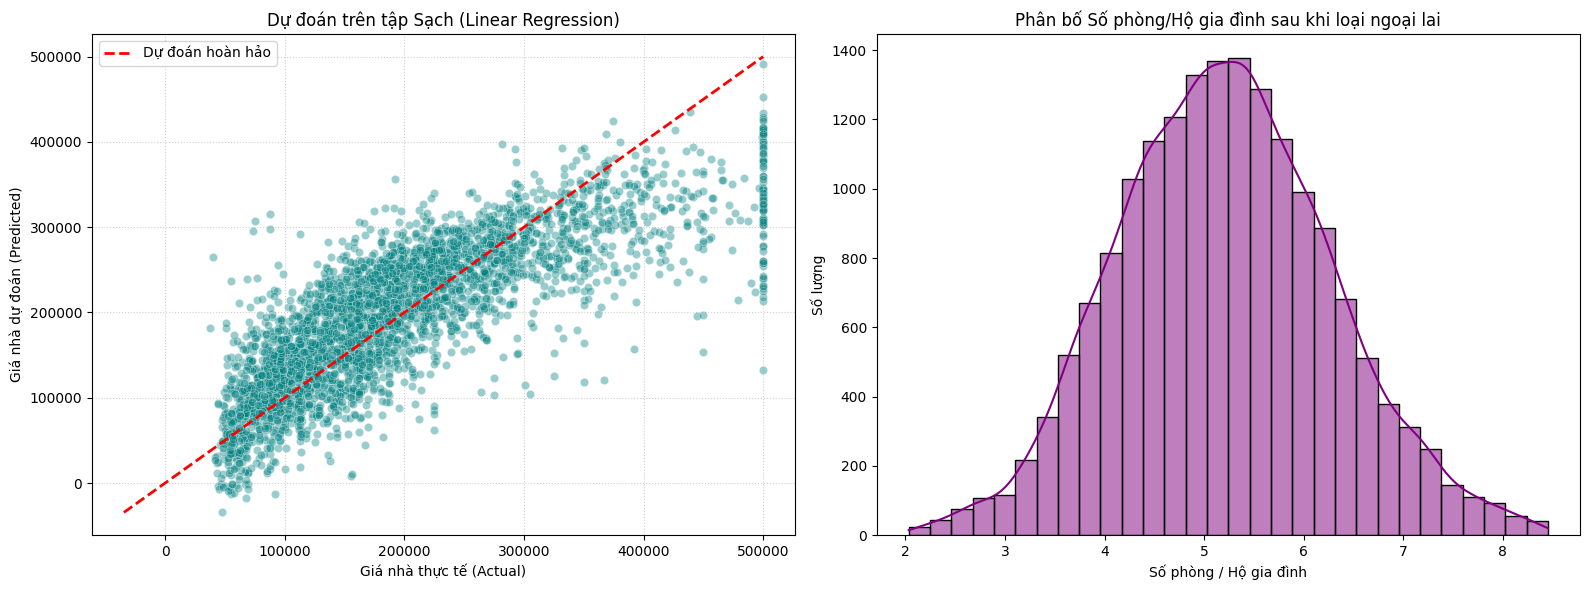

In [20]:

# Thiết lập kích thước khung hình cho 2 biểu đồ (1 hàng, 2 cột)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatterplot: So sánh thực tế vs dự đoán trên tập dữ liệu đã làm sạch
sns.scatterplot(x=y_test_c, y=y_pred_c, alpha=0.4, color='teal', edgecolor='w', ax=axes[0])
min_val_c = min(y_test_c.min(), y_pred_c.min())
max_val_c = max(y_test_c.max(), y_pred_c.max())
axes[0].plot([min_val_c, max_val_c], [min_val_c, max_val_c], color='red', linestyle='--', linewidth=2, label='Dự đoán hoàn hảo')
axes[0].set_title('Dự đoán trên tập Sạch (Linear Regression)')
axes[0].set_xlabel('Giá nhà thực tế (Actual)')
axes[0].set_ylabel('Giá nhà dự đoán (Predicted)')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# 2. Histplot: Biểu diễn phân bố số phòng trên hộ gia đình
sns.histplot(df_clean['rooms_per_household'], bins=30, kde=True, ax=axes[1], color='purple')
axes[1].set_title('Phân bố Số phòng/Hộ gia đình sau khi loại ngoại lai')
axes[1].set_xlabel('Số phòng / Hộ gia đình')
axes[1].set_ylabel('Số lượng')

plt.tight_layout()
plt.show()

In [18]:
import joblib
from google.colab import files


joblib.dump(model, 'linear_model.pkl')

joblib.dump(scaler, 'scaler.pkl')

files.download('linear_model.pkl')
files.download('scaler.pkl')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>